### **Generować dane z anomalią**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Generowanie zaszumionego zbioru danych
# seed = numer albumu modulo 50
np.random.seed(30628%50)

n_customers = 200

wiek = np.random.normal(38, 12, n_customers).round(0)
dochód = np.random.gamma(shape=3, scale=2500, size=n_customers) + 1500
ocena_ryzyka = np.random.choice(['Niskie', 'Srednie', 'Wysokie', np.nan], n_customers, p=[0.3, 0.5, 0.15, 0.05])
status_zatrudnienia = np.random.choice(['Etat', 'Kontrakt', 'Bezrobotny'], n_customers, p=[0.6, 0.3, 0.1])
kwota_pozyczki = dochód * np.random.uniform(1.2, 4.5, n_customers)

df = pd.DataFrame({
    'Klient_ID': range(5001, 5001 + n_customers),
    'Wiek': wiek,
    'Dochod_Miesieczny': dochód.round(2),
    'Status_Zatrudnienia': status_zatrudnienia,
    'Ocena_Ryzyka': ocena_ryzyka,
    'Kwota_Pozyczki': kwota_pozyczki.round(2)
})

# Celowe wstrzykiwanie błędów i braków danych
df.loc[15, 'Dochod_Miesieczny'] = -5000.0  # Błąd systemu (ujemny dochód)
df.loc[42, 'Wiek'] = 145                   # Błąd ludzki (outlier wieku)
df.loc[99, 'Dochod_Miesieczny'] = 125000.0 # Outlier dochodu (miliarder)

df.loc[df.sample(frac=0.08, random_state=42).index, 'Dochod_Miesieczny'] = np.nan
df.loc[df.sample(frac=0.05, random_state=99).index, 'Kwota_Pozyczki'] = np.nan

print("--- ZBIÓR DANYCH ZOSTAŁ PRZYGOTOWANY ---")
print(f"Wymiary tabeli: {df.shape}")
df.head()

--- ZBIÓR DANYCH ZOSTAŁ PRZYGOTOWANY ---
Wymiary tabeli: (200, 6)


,Klient_ID,Wiek,Dochod_Miesieczny,Status_Zatrudnienia,Ocena_Ryzyka,Kwota_Pozyczki
0,5001,43.0,15011.87,Etat,Niskie,46202.08
1,5002,58.0,6920.15,Bezrobotny,Wysokie,13267.27
2,5003,35.0,7510.38,Etat,Srednie,25547.87
3,5004,26.0,5950.58,Etat,Srednie,20998.12
4,5005,39.0,3566.89,Kontrakt,Niskie,14880.27


### **Zadanie 1**: Profilowanie i Identyfikacja Anomalii (Czyszczenie)
1. Sprawdź, ile braków danych (NaN) znajduje się w każdej z kolumn.
2. Zidentyfikuj i usuń ze zbioru jawne błędy logiczne i systemowe:
*  Usuń wiersze, w których _Dochod_Miesieczny_ jest mniejszy lub równy 0.
*  Usuń wiersze, w których _Wiek_ przekracza 100 lat.

3. Wyświetlić wielkość tablicy po usunięciu anomalii
4. Wyświetlić statystyki _Dochod_Miesieczny_ i _Wiek_ po usuwaniu anomalii

In [2]:
#Z jakiegoś powodu w moim edytorze wykresy domyślnie mają odwrócone kolory, to powinno ustawić je znowu na białe (jak w Colabie), jak wygląda nieczytelnie w Colabie to przepraszam!
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'savefig.facecolor':'white',
    'text.color':       'black',
    'axes.labelcolor':  'black',
    'axes.edgecolor':   'black',
    'xtick.color':      'black',
    'ytick.color':      'black',
})


#--- Zadanie 1.1 ---
print("1.1")
missing_values = df.isna().sum()
print(missing_values,"\n")

#--- Zadanie 1.2 ---
print("1.2")
outliers_revenue = (df['Dochod_Miesieczny'] <= 0) | (df['Wiek'] > 100)
cleaned_df = df[~outliers_revenue].copy()
print(cleaned_df,"\n")

#--- Zadanie 1.3 ---
print("1.3")
print(df.shape)
print(cleaned_df.shape,"\n")

#--- Zadanie 1.4 ---
print(cleaned_df[['Wiek','Dochod_Miesieczny']].describe())



1.1
Klient_ID               0
Wiek                    0
Dochod_Miesieczny      16
Status_Zatrudnienia     0
Ocena_Ryzyka            0
Kwota_Pozyczki         10
dtype: int64 

1.2
     Klient_ID  Wiek  Dochod_Miesieczny Status_Zatrudnienia Ocena_Ryzyka  \
0         5001  43.0           15011.87                Etat       Niskie   
1         5002  58.0            6920.15          Bezrobotny      Wysokie   
2         5003  35.0            7510.38                Etat      Srednie   
3         5004  26.0            5950.58                Etat      Srednie   
4         5005  39.0            3566.89            Kontrakt       Niskie   
..         ...   ...                ...                 ...          ...   
195       5196  30.0           12312.35                Etat      Srednie   
196       5197  19.0            6012.63                Etat      Srednie   
197       5198  41.0           10188.83            Kontrakt      Wysokie   
198       5199  40.0            9188.54                Etat  

### **Zadanie 2**: Strategie Imputacji Braków (Missing Values)
Model uczenia maszynowego nie akceptuje wartości pustych. Uzupełnij braki w danych według poniższych strategii biznesowych:
1. Kolumna *Dochod_Miesieczny* charakteryzuje się silną skośnością prawostronną. Uzupełnij jej braki medianą wyliczoną z tej kolumny.
2. Kolumna *Kwota_Pozyczki* ma rozkład zbliżony do symetrycznego. Uzupełnij braki średnią arytmetyczną.
3. Kolumna *Ocena_Ryzyka* to zmienna kategoryczna (tekstowa). Zamiast zgadywać klasę, uzupełnij braki stałą wartością tekstową "Nieznana".

4. Wyświetlić wykres słupkowy dla  *Dochod_Miesieczny* i *Kwota pożyczki* po amputacji braków.   
5. Wyświetlić histogram dla *Ocena_Ryzyka* po aputacji braków.

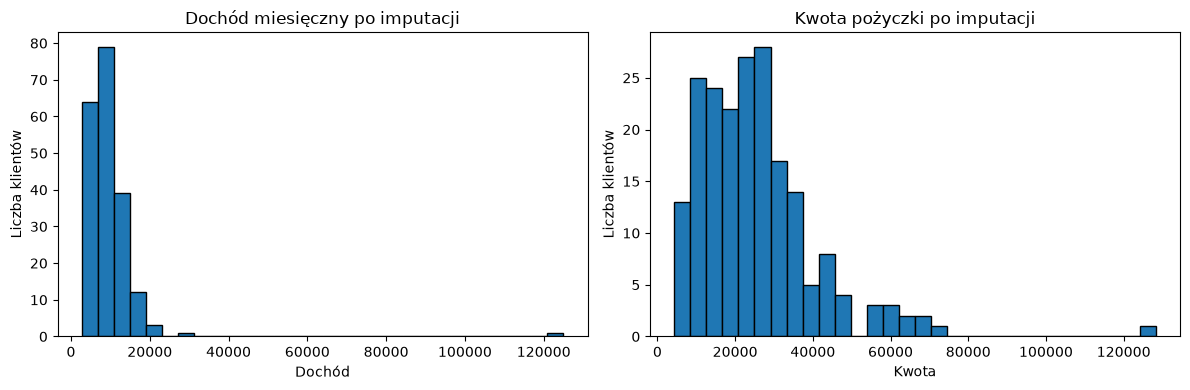

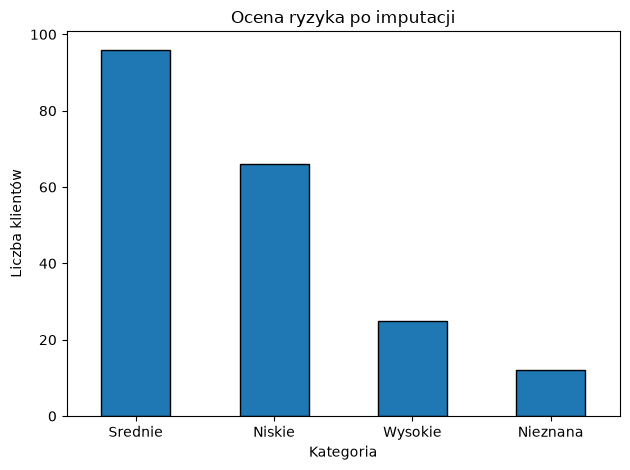

In [3]:
imputed_df = cleaned_df.copy()
#--- Zadanie 2.1 ---
median = imputed_df['Dochod_Miesieczny'].median()
imputed_df['Dochod_Miesieczny'] = imputed_df['Dochod_Miesieczny'].fillna(median)

#--- Zadanie 2.2 ---
mean = imputed_df['Kwota_Pozyczki'].mean()
imputed_df['Kwota_Pozyczki'] = imputed_df['Kwota_Pozyczki'].fillna(mean)

#--- Zadanie 2.3 ---
imputed_df['Ocena_Ryzyka'] = imputed_df['Ocena_Ryzyka'].replace('nan', 'Nieznana')

#--- Zadanie 2.4 ---

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(imputed_df['Dochod_Miesieczny'], bins=30, edgecolor='black')
axes[0].set_title('Dochód miesięczny po imputacji')
axes[0].set_xlabel('Dochód'); axes[0].set_ylabel('Liczba klientów')

axes[1].hist(imputed_df['Kwota_Pozyczki'], bins=30, edgecolor='black')
axes[1].set_title('Kwota pożyczki po imputacji')
axes[1].set_xlabel('Kwota'); axes[1].set_ylabel('Liczba klientów')

plt.tight_layout()
plt.show()


# --- 2.5:  ---
plt.figure()
imputed_df['Ocena_Ryzyka'].value_counts().plot.bar(edgecolor='black')
plt.title('Ocena ryzyka po imputacji')
plt.xlabel('Kategoria'); plt.ylabel('Liczba klientów')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### **Zadanie 3**: Wykrywanie i Filtrowanie Outlierów (Reguła IQR)
W kolumnie *Dochod_Miesieczny* wciąż znajduje się ekstremalnie wysoki zarobek (miliarder), który może zaburzyć działanie modeli liniowych i odległościowych.
1. Oblicz matematyczny rozstęp ćwiartkowy (IQR = Q₃ - Q₁) dla dochodu.
2. Wyznacz *dolną* i *górną* granicę poprawności danych za pomocą reguły:
  
    Dolna = Q₁ - 1.5 ⋅ IQR;  
    Górna = Q₃ + 1.5 ⋅ IQR.
3. Przefiltruj zbiór danych, usuwając wszystkie rekordy, których dochód jest mniejszy od dolnej lub przekracza górną granicę.
4. Wyznaczyć ile rekordów zostaje?


In [4]:
#--- Zadanie 3 ---
filtered_df = cleaned_df.copy()
q1 = filtered_df['Dochod_Miesieczny'].quantile(0.25)
q3 = filtered_df['Dochod_Miesieczny'].quantile(0.75)
iqr = q3 - q1
print(f"3.1\nq1: {q1}\nq3: {q3}\niqr: {iqr}\n")

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print(f"3.2\nlower_bound: {lower_bound}\nupper_bound: {upper_bound}\n")


corr = ((filtered_df['Dochod_Miesieczny'] >= lower_bound) & (filtered_df['Dochod_Miesieczny'] <= upper_bound))
filtered_df = filtered_df[corr].copy()

print(f"3.4\nRekordy: {filtered_df.shape[0]}\n")

3.1
q1: 5577.795
q3: 11519.685000000001
iqr: 5941.890000000001

3.2
lower_bound: -3335.0400000000027
upper_bound: 20432.520000000004

3.4
Rekordy: 179



### **Zadanie 4**: Kodowanie Zmiennych Kategorycznych (Encoding)
1. Kolumna Status_Zatrudnienia nie posiada naturalnej hierarchii. Przekształć ją za pomocą kodowania zero-jedynkowego (*One-Hot Encoding*).
2. Pamiętaj o usunięciu pierwszej kolumny skorelowanej (drop_first=True), aby uniknąć pułapki zmiennych fikcyjnych.
3. Usuń kolumnę *Klient_ID* oraz *Ocena_Ryzyka*, pozostawiając w ramce wyłącznie cechy numeryczne.
4. Wyświetlić rozmiar tablicy oraz jej 10 pierwszych rekordów.

In [5]:
# --- Zadanie 4 ---
encoded_df = pd.get_dummies(filtered_df,columns=['Status_Zatrudnienia'],drop_first=True,dtype=int)

encoded_df = encoded_df.drop(columns=['Klient_ID', 'Ocena_Ryzyka'])

print(f"4.4\nRozmiar tablicy: {encoded_df.shape}")
print(f"Kolumny: {list(encoded_df.columns)}\n")
encoded_df.head(10)

4.4
Rozmiar tablicy: (179, 5)
Kolumny: ['Wiek', 'Dochod_Miesieczny', 'Kwota_Pozyczki', 'Status_Zatrudnienia_Etat', 'Status_Zatrudnienia_Kontrakt']



,Wiek,Dochod_Miesieczny,Kwota_Pozyczki,Status_Zatrudnienia_Etat,Status_Zatrudnienia_Kontrakt
0,43.0,15011.87,46202.08,1,0
1,58.0,6920.15,13267.27,0,0
2,35.0,7510.38,25547.87,1,0
3,26.0,5950.58,20998.12,1,0
4,39.0,3566.89,14880.27,0,1
5,56.0,14434.26,62136.59,1,0
6,42.0,12067.72,44264.12,1,0
7,34.0,8500.64,17629.79,1,0
8,28.0,7922.58,34254.44,0,1
9,32.0,5571.90,7298.63,0,1


### **Zadanie 5**: Przeskalowanie Danych (Standaryzacja vs Normalizacja)
Większość algorytmów (np. KNN, SVM, Sieci Neuronowe) wymaga, aby cechy miały podobną skalę. Wykorzystaj bibliotekę *scikit-learn*:
1. Zastosuj *Standaryzację* (StandardScaler) na kolumnie *Dochod_Miesieczny* (przekształcenie do średniej μ=0 i odchylenia σ=1).
2. Zastosuj *Normalizację Min-Max* (MinMaxScaler) na kolumnie *Wiek* oraz *Kwota_Pozyczki* (ściśnięcie wartości do sztywnego przedziału \([0, 1]\)).
3. Wyświetl statystyki opisowe (.describe()) dla ostatecznie przetworzonej macierzy cech, aby zweryfikować poprawność skalowania.
4. Wyświetlić wykres słupkowy *Dochod_Miesieczny* po standaryzacji.
5. Wyświetlić wykres słupkowy *Wiek* po normalizacji

Po skalowaniu:
           Wiek  Dochod_Miesieczny  Kwota_Pozyczki  Status_Zatrudnienia_Etat  \
count  179.0000           179.0000        171.0000                  179.0000   
mean     0.5302            -0.0000          0.2940                    0.6480   
std      0.1864             1.0028          0.2046                    0.4789   
min      0.0000            -1.5652          0.0000                    0.0000   
25%      0.4154            -0.8181          0.1439                    0.0000   
50%      0.5385            -0.2130          0.2609                    1.0000   
75%      0.6462             0.6896          0.3967                    1.0000   
max      1.0000             2.7763          1.0000                    1.0000   

       Status_Zatrudnienia_Kontrakt  
count                      179.0000  
mean                         0.2626  
std                          0.4413  
min                          0.0000  
25%                          0.0000  
50%                          0.0000 

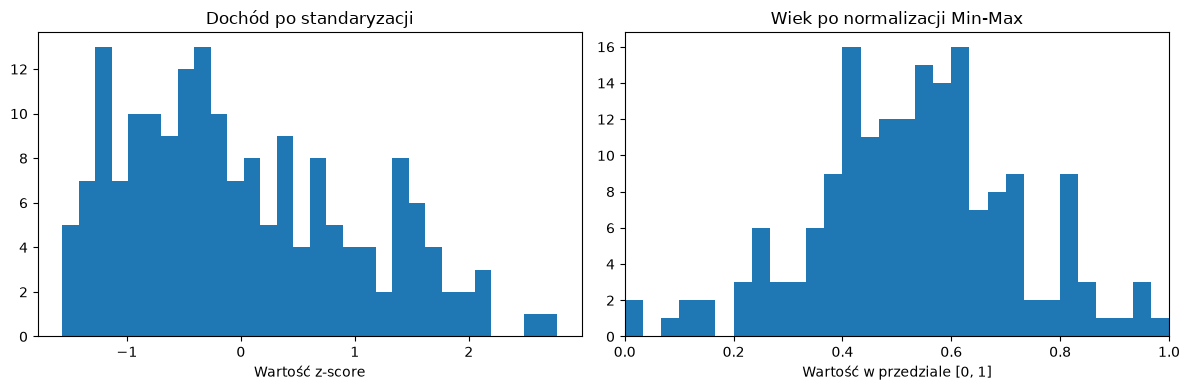

In [6]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scaled_df = encoded_df.copy()

#--- Zadanie 5.1 ---
scaler_standard = StandardScaler()
scaled_df['Dochod_Miesieczny'] = scaler_standard.fit_transform(scaled_df[['Dochod_Miesieczny']])

#--- Zadanie 5.2 ---
scaler_mm = MinMaxScaler()
scaled_df[['Wiek', 'Kwota_Pozyczki']] = scaler_mm.fit_transform(scaled_df[['Wiek', 'Kwota_Pozyczki']])

#--- Zadanie 5.3 ---
print(f"Po skalowaniu:\n{scaled_df.describe().round(4)}\n")

#--- Zadanie 5.4 ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(scaled_df['Dochod_Miesieczny'], bins=30)
axes[0].set_title('Dochód po standaryzacji')
axes[0].set_xlabel('Wartość z-score')

#--- Zadanie 5.5 ---
axes[1].hist(scaled_df['Wiek'], bins=30)
axes[1].set_title('Wiek po normalizacji Min-Max')
axes[1].set_xlabel('Wartość w przedziale [0, 1]')
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()